# Does Changing the Classification Threshold Change the Model's Decisions?

A classification model can give us a probability, but we still need to decide when that probability should become a positive prediction.

For this experiment, I'm using the customer churn model and changing only the classification threshold.

I want to see how different thresholds affect precision, recall, and F1 score without retraining the model.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

## Preparing the data

I'm using the same Telco Customer Churn dataset as before.

I'll keep the preprocessing simple and use the same train/test setup so we can focus on what happens when the classification threshold changes.

In [16]:
data_path = Path("../../data/raw/Telco-Customer-Churn.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [17]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

df = df.drop(columns=["customerID"])

df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Missing values:", df.isnull().sum().sum())
print("Churn rate:", round(df["Churn"].mean(), 3))

Missing values: 0
Churn rate: 0.265


In [18]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 5634
Test rows: 1409


## Training the model

I'll use Logistic Regression for this experiment.

The goal isn't to compare models this time. I want to keep the model fixed and see what happens when only the classification threshold changes.

In [19]:
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [20]:
churn_probabilities = model.predict_proba(X_test)[:, 1]

probability_sample = pd.DataFrame({
    "Actual": y_test.values,
    "Churn Probability": churn_probabilities
})

probability_sample.head(10)

,Actual,Churn Probability
0,0,0.045240
1,0,0.684405
2,0,0.058693
3,0,0.401755
4,0,0.021519
5,0,0.603707
6,0,0.448907
7,0,0.130087
8,0,0.002879
9,1,0.394952


## Changing the threshold

The model gives a churn probability for each customer. The threshold decides when that probability becomes a churn prediction.

I'll apply a few different thresholds to the same model probabilities and see which predictions change.

In [21]:
threshold_sample = probability_sample.head(10).copy()

for threshold in [0.3, 0.4, 0.5, 0.6]:
    threshold_sample[f"Prediction @ {threshold}"] = (
        threshold_sample["Churn Probability"] >= threshold
    ).astype(int)

threshold_sample

,Actual,Churn Probability,Prediction @ 0.3,Prediction @ 0.4,Prediction @ 0.5,Prediction @ 0.6
0,0,0.045240,0,0,0,0
1,0,0.684405,1,1,1,1
2,0,0.058693,0,0,0,0
3,0,0.401755,1,1,0,0
4,0,0.021519,0,0,0,0
5,0,0.603707,1,1,1,1
6,0,0.448907,1,1,0,0
7,0,0.130087,0,0,0,0
8,0,0.002879,0,0,0,0
9,1,0.394952,1,0,0,0


## Comparing different thresholds

Now I'll apply different thresholds to the full test set and compare how precision, recall, and F1 change.

In [22]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:
    predictions = (churn_probabilities >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions)
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(3)

,Threshold,Accuracy,Precision,Recall,F1
0,0.3,0.749,0.519,0.754,0.615
1,0.4,0.778,0.569,0.668,0.615
2,0.5,0.806,0.657,0.559,0.604
3,0.6,0.799,0.718,0.401,0.515
4,0.7,0.766,0.739,0.182,0.292


## Precision and recall tradeoff

Lowering the threshold makes the model more willing to predict churn. That helps catch more actual churners, but it also creates more false positives.

Raising the threshold does the opposite.

I'll plot the metrics to make that tradeoff easier to see.

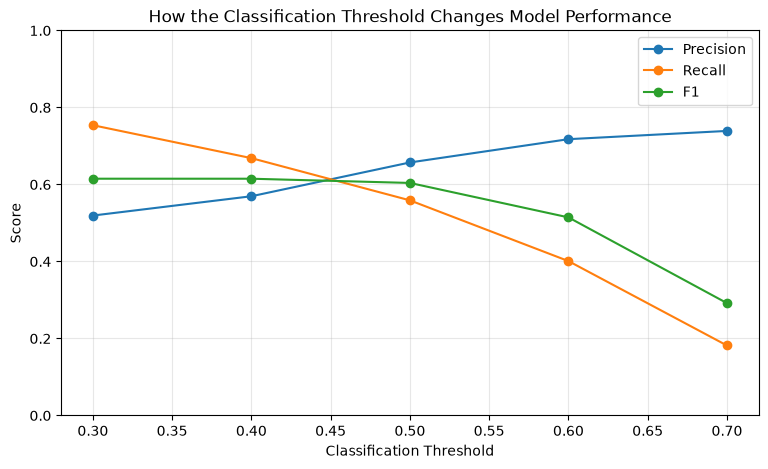

In [23]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("How the Classification Threshold Changes Model Performance")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

## What does this mean in actual customers?

The metric scores show the tradeoff, but I also wanted to see what that means in actual customer predictions.

For each threshold, I'll count how many churners were correctly identified, how many were missed, and how many non-churners were incorrectly flagged.

In [25]:
threshold_counts = []

for threshold in thresholds:
    predictions = (churn_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    threshold_counts.append({
        "Threshold": threshold,
        "True Positives": tp,
        "False Positives": fp,
        "True Negatives": tn,
        "False Negatives": fn
    })

threshold_counts = pd.DataFrame(threshold_counts)

threshold_counts

,Threshold,True Positives,False Positives,True Negatives,False Negatives
0,0.3,282,261,774,92
1,0.4,250,189,846,124
2,0.5,209,109,926,165
3,0.6,150,59,976,224
4,0.7,68,24,1011,306


## What I found

The threshold made a bigger difference than I expected.

At 0.5, the model caught 209 churners and missed 165.

When I changed it to 0.3, it caught 282 churners and missed only 92. So we were able to catch 73 more churners without changing or retraining the model.

But there was a downside too. False positives went from 109 to 261. So while we caught more churners, we also incorrectly flagged more customers who weren't going to churn.

So 0.3 isn't necessarily better than 0.5. It just makes a different tradeoff.

## Takeaway

What stood out to me is that 0.5 doesn't have to be the right threshold just because it's the default.

If missing a churner is more costly, a lower threshold might make sense. If unnecessary retention calls are expensive, we may want to be more selective.

The model gives us the probability. How we use that probability should depend on the actual problem.